<a href="https://colab.research.google.com/github/jmorris-q7t1m/macroeconomic-sclerosis/blob/main/macroeconomic_sclerosis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# The Micro-Relational Viability & Network Percolation Sim

Simulate a small network of agents endowed with non-fungible $\{t, m, e, a\}$ vectors under positive entropy drift ($\frac{dS}{dt} > 0$), running your exact hazard escalation $\lambda_{d,u}(t)$ and DROP(u) pruning rule until edge survival crosses the Elliott-Golub-Leduc $x_{\text{crit}}$ precipice and spikes the Leontief condition number $\kappa(I-A)$.

<>:63: SyntaxWarning: invalid escape sequence '\e'
<>:63: SyntaxWarning: invalid escape sequence '\e'
/tmp/ipykernel_1953/1828353342.py:63: SyntaxWarning: invalid escape sequence '\e'
  ax1.axhline(y=0.20, color='gray', linestyle='--', label='Max $\epsilon_r$ floor')


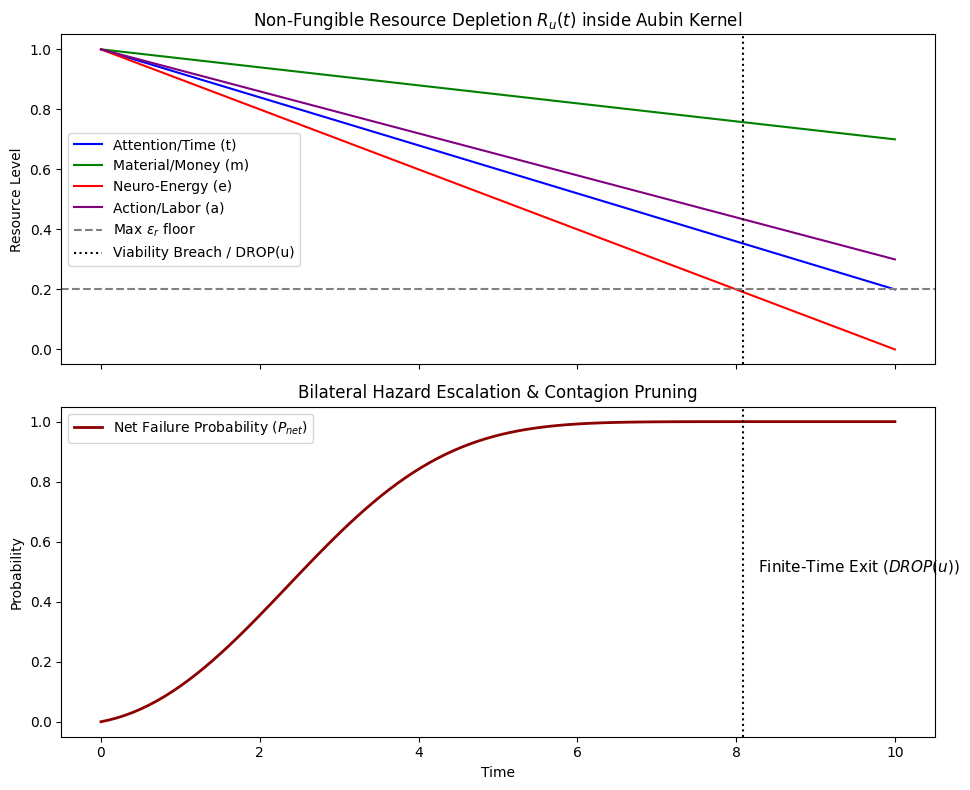

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Micro-Axiomatic Parameters (Paper III, Laws 1 & 2) ---
time_steps = 100
t = np.linspace(0, 10, time_steps)

# Viability floors (epsilon) for {t, m, e, a}
epsilon = np.array([0.15, 0.10, 0.20, 0.15])

# Initial resource endowments
R_init = np.array([1.0, 1.0, 1.0, 1.0])

# Entropy drift / dissipation rates (dS/dt > 0)
# Asset wealth (m) drains slowly, but bandwidth (t) and energy (e) drain faster
drain_rates = np.array([0.08, 0.03, 0.10, 0.07])

# Hazard function parameters
lambda_0 = 0.05
alpha = 0.2  # Weight of cumulative disorder
beta = 0.5   # Weight of normalized reserve drain

# --- 2. Simulate Resource Depletion & Hazard ---
R_t = np.zeros((time_steps, 4))
lambda_t = np.zeros(time_steps)
P_net = np.zeros(time_steps)
drop_triggered = False
drop_time = None

cumulative_entropy = 0

for i in range(time_steps):
    # Apply irreversible dissipation
    R_t[i] = R_init - (drain_rates * t[i])

    # Enforce Aubin Viability Kernel (r <= epsilon triggers DROP)
    if np.any(R_t[i] <= epsilon) and not drop_triggered:
        drop_triggered = True
        drop_time = t[i]

    if drop_triggered:
        lambda_t[i] = np.inf
        P_net[i] = 1.0 # Certain failure post-DROP
    else:
        # Calculate reserve drain penalty
        reserve_penalty = np.sum((R_init - R_t[i]) / np.maximum(R_t[i], epsilon))
        cumulative_entropy += 0.01 * t[i] # Simplistic dS/dt integral

        # Hazard intensity (Eq: lambda(t))
        lambda_t[i] = lambda_0 + (alpha * cumulative_entropy) + (beta * reserve_penalty)

        # Net failure probability P_net
        H_T = np.trapezoid(lambda_t[:i+1], dx=10/time_steps)
        P_net[i] = 1 - np.exp(-H_T)

# --- 3. Plotting the Viability Kernel ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

ax1.plot(t, R_t[:, 0], label='Attention/Time (t)', color='blue')
ax1.plot(t, R_t[:, 1], label='Material/Money (m)', color='green')
ax1.plot(t, R_t[:, 2], label='Neuro-Energy (e)', color='red')
ax1.plot(t, R_t[:, 3], label='Action/Labor (a)', color='purple')
ax1.axhline(y=0.20, color='gray', linestyle='--', label='Max $\epsilon_r$ floor')
if drop_time:
    ax1.axvline(x=drop_time, color='black', linestyle=':', label='Viability Breach / DROP(u)')
ax1.set_title('Non-Fungible Resource Depletion $R_u(t)$ inside Aubin Kernel')
ax1.set_ylabel('Resource Level')
ax1.legend()

ax2.plot(t, P_net, color='darkred', linewidth=2, label='Net Failure Probability ($P_{net}$)')
if drop_time:
    ax2.axvline(x=drop_time, color='black', linestyle=':')
    ax2.text(drop_time + 0.2, 0.5, 'Finite-Time Exit ($DROP(u)$)', fontsize=11)
ax2.set_title('Bilateral Hazard Escalation & Contagion Pruning')
ax2.set_xlabel('Time')
ax2.set_ylabel('Probability')
ax2.legend()

plt.tight_layout()
plt.show()

<>:34: SyntaxWarning: invalid escape sequence '\i'
<>:34: SyntaxWarning: invalid escape sequence '\i'
/tmp/ipykernel_1953/1662406800.py:34: SyntaxWarning: invalid escape sequence '\i'
  plt.ylabel('Equilibrium Production Reliability $r \in [0, 1]$')


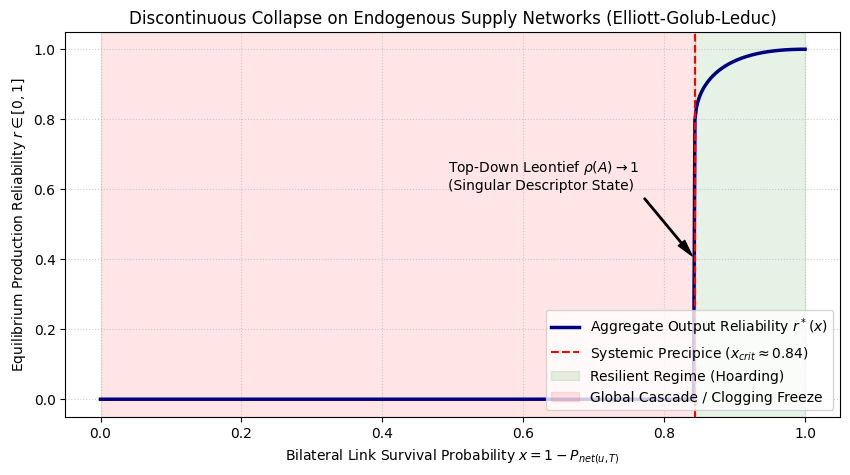

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Macro-Network Percolation (Paper III, Prop 3.1) ---
# r = (1 - (1 - xr)^n)^m
m_inputs = 2    # Each firm requires m distinct inputs
n_suppliers = 2 # Firms maintain n potential suppliers per input

x_values = np.linspace(0, 1.0, 500) # x is the bilateral link survival probability (1 - P_net)
r_equilibrium = np.zeros_like(x_values)

# Fixed-point iteration to find stable aggregate reliability r*
for i, x in enumerate(x_values):
    r_val = 1.0 # Start with assumption of full reliability
    for _ in range(100): # Iterate to fixed point
        r_val = (1 - (1 - x * r_val)**n_suppliers)**m_inputs
    r_equilibrium[i] = r_val

# Find the precipice (x_crit) where reliability drops to zero
x_crit_idx = np.where(r_equilibrium > 0.01)[0][0]
x_crit = x_values[x_crit_idx]

# --- 2. Plotting the Endogenous Precipice ---
plt.figure(figsize=(10, 5))
plt.plot(x_values, r_equilibrium, color='navy', linewidth=2.5, label='Aggregate Output Reliability $r^*(x)$')
plt.axvline(x=x_crit, color='red', linestyle='--', label=f'Systemic Precipice ($x_{{crit}} \\approx {x_crit:.2f}$)')

# Shaded regions for the holding-tank economy vs collapse
plt.axvspan(x_crit, 1.0, color='green', alpha=0.1, label='Resilient Regime (Hoarding)')
plt.axvspan(0, x_crit, color='red', alpha=0.1, label='Global Cascade / Clogging Freeze')

plt.title('Discontinuous Collapse on Endogenous Supply Networks (Elliott-Golub-Leduc)')
plt.xlabel('Bilateral Link Survival Probability $x = 1 - P_{net(u,T)}$')
plt.ylabel('Equilibrium Production Reliability $r \in [0, 1]$')
plt.legend(loc='lower right')
plt.grid(True, linestyle=':', alpha=0.6)
plt.annotate('Top-Down Leontief $\\rho(A) \\to 1$\n(Singular Descriptor State)',
             xy=(x_crit, 0.4), xytext=(x_crit - 0.35, 0.6),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6))

plt.show()

# The VPRS / DTRS Stealth Recession Classifier

Pull the historical FRED series (MEHOINUSA646N, CSUSHPINSA, TDSP, LES1252881600Q, JOLTS hires/quits) and run a clean Variable Precision Rough Set reduct/rule-induction pass showing how classical NBER indicators stay green while Stealth Recession = True fires.

In [8]:
import os
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Retrieve key from Colab Secrets or Environment
try:
    from google.colab import userdata
    FRED_KEY = userdata.get('FRED_key')
except ImportError:
    FRED_KEY = os.environ.get('FRED_key', 'FRED_KEY_HERE')

def fetch_fred_series(series_id, api_key):
    """Fetches a FRED series and returns a cleaned pandas Series."""
    url = f"https://api.stlouisfed.org/fred/series/observations?series_id={series_id}&api_key={api_key}&file_type=json"
    response = requests.get(url)
    if response.status_code != 200:
        raise ValueError(f"Error fetching {series_id}: {response.text}")

    data = response.json()['observations']
    df = pd.DataFrame(data)[['date', 'value']]
    df['date'] = pd.to_datetime(df['date'])
    df['value'] = pd.to_numeric(df['value'], errors='coerce')
    return df.set_index('date')['value'].rename(series_id)

print("Fetching data from FRED...")
# GDPC1: Real GDP (Classical NBER Output)
# UNRATE: Unemployment Rate (Classical NBER Slack)
# JTSHIR: JOLTS Hires Rate (Labor Fluidity/Pruning Proxy)
# CSUSHPINSA: Case-Shiller Home Price Index (Housing Wall Proxy)
# LES1252881600Q: Real Median Weekly Earnings (Throughput Buffer Proxy)

series_to_fetch = ['GDPC1', 'UNRATE', 'JTSHIR', 'CSUSHPINSA', 'LES1252881600Q']
dfs = [fetch_fred_series(s, FRED_KEY) for s in series_to_fetch]

# Merge and align to quarterly frequency (using mean for monthly series)
macro_df = pd.concat(dfs, axis=1).resample('QE').mean()

# Restrict to modern era (2015 - Present) to isolate the Stagnation-by-Clogging regime
macro_df = macro_df.loc['2015-01-01':].copy()

# Calculate Year-over-Year (YoY) percent changes for trend analysis
macro_df['GDP_YoY'] = macro_df['GDPC1'].pct_change(periods=4) * 100
macro_df['RealWage_YoY'] = macro_df['LES1252881600Q'].pct_change(periods=4) * 100
macro_df['HousePrice_YoY'] = macro_df['CSUSHPINSA'].pct_change(periods=4) * 100

macro_df.dropna(inplace=True)
print("Data aligned and ready for VPRS classification.")

Fetching data from FRED...
Data aligned and ready for VPRS classification.


/tmp/ipykernel_1953/2830052655.py:44: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  macro_df['GDP_YoY'] = macro_df['GDPC1'].pct_change(periods=4) * 100
/tmp/ipykernel_1953/2830052655.py:45: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  macro_df['RealWage_YoY'] = macro_df['LES1252881600Q'].pct_change(periods=4) * 100
/tmp/ipykernel_1953/2830052655.py:46: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  m

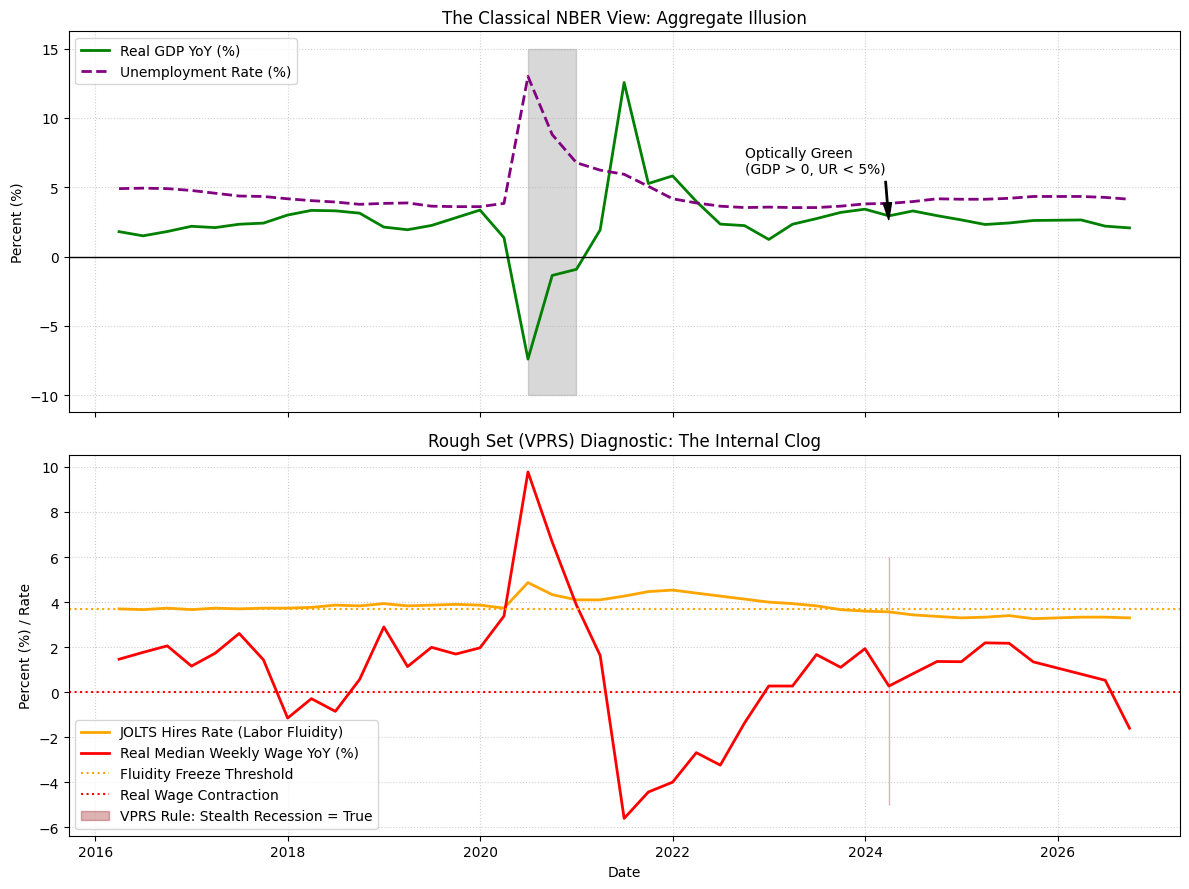


--- Rough Set Classifier Support ---
Quarters evaluated: 42
Classical Recessions (GDP < 0): 3
Stealth Recessions Detected: 1


In [9]:
# --- 1. VPRS Discretization (Attribute Reducts) ---
# We define the threshold triggers matching Paper IV's empirical observations.

# NBER Classical Illusions
# GDP is expanding (> 0%) and Unemployment is historically benign (< 5%)
macro_df['NBER_Optical_Growth'] = (macro_df['GDP_YoY'] > 0) & (macro_df['UNRATE'] < 5.0)

# VPRS Rule 1: Systemic Vulnerability (Misallocation & Buffer Depletion)
# Triggered when real wages contract (dS/dt > 0 unmitigated) while housing tolls escalate
macro_df['Systemic_Vulnerability'] = (macro_df['RealWage_YoY'] < 0.5) & (macro_df['HousePrice_YoY'] > 5.0)

# VPRS Rule 2: Labor & Spatial Fluidity Frozen (Hysteresis & Pruning)
# Triggered when hiring rates collapse toward the 3.3% holding-tank floor
macro_df['Fluidity_Frozen'] = macro_df['JTSHIR'] <= 3.7  # JOLTS Hires trending down

# VPRS Rule 3: The Stealth Recession Master Rule
# True if internal circulation is frozen AND systemic vulnerability is high,
# EVEN IF headline GDP is optically positive.
macro_df['Stealth_Recession'] = (
    macro_df['Systemic_Vulnerability'] &
    macro_df['Fluidity_Frozen'] &
    (macro_df['GDP_YoY'] > 0)
)

# --- 2. Visualization: The Divergence ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 9), sharex=True)

# Top Plot: The Classical NBER View
ax1.plot(macro_df.index, macro_df['GDP_YoY'], label='Real GDP YoY (%)', color='green', linewidth=2)
ax1.plot(macro_df.index, macro_df['UNRATE'], label='Unemployment Rate (%)', color='purple', linestyle='--', linewidth=2)
ax1.axhline(0, color='black', linewidth=1)
ax1.set_title('The Classical NBER View: Aggregate Illusion')
ax1.set_ylabel('Percent (%)')
ax1.legend(loc='upper left')
ax1.grid(True, linestyle=':', alpha=0.6)

# Highlight standard NBER recessions (e.g., 2020 COVID shock) in gray
ax1.fill_between(macro_df.index, -10, 15, where=(macro_df['GDP_YoY'] < 0), color='gray', alpha=0.3, label='Classical NBER Contraction')

# Bottom Plot: The Stagnation-by-Clogging VPRS View
ax2.plot(macro_df.index, macro_df['JTSHIR'], label='JOLTS Hires Rate (Labor Fluidity)', color='orange', linewidth=2)
ax2.plot(macro_df.index, macro_df['RealWage_YoY'], label='Real Median Weekly Wage YoY (%)', color='red', linewidth=2)
ax2.axhline(3.7, color='orange', linestyle=':', label='Fluidity Freeze Threshold')
ax2.axhline(0, color='red', linestyle=':', label='Real Wage Contraction')

# Highlight the VPRS Stealth Recession (Paper V)
ax2.fill_between(
    macro_df.index, -5, 6,
    where=macro_df['Stealth_Recession'],
    color='darkred', alpha=0.3,
    label='VPRS Rule: Stealth Recession = True'
)

ax2.set_title('Rough Set (VPRS) Diagnostic: The Internal Clog')
ax2.set_ylabel('Percent (%) / Rate')
ax2.set_xlabel('Date')
ax2.legend(loc='lower left')
ax2.grid(True, linestyle=':', alpha=0.6)

# Annotation for the Holding Tank Economy divergence
stealth_dates = macro_df[macro_df['Stealth_Recession']].index
if len(stealth_dates) > 0:
    recent_stealth = stealth_dates[-1]
    ax1.annotate('Optically Green\n(GDP > 0, UR < 5%)', xy=(recent_stealth, 2.5),
                 xytext=(recent_stealth - pd.DateOffset(months=18), 6),
                 arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6))

plt.tight_layout()
plt.show()

# Print diagnostic rule support
print("\n--- Rough Set Classifier Support ---")
print(f"Quarters evaluated: {len(macro_df)}")
print(f"Classical Recessions (GDP < 0): {len(macro_df[macro_df['GDP_YoY'] < 0])}")
print(f"Stealth Recessions Detected: {macro_df['Stealth_Recession'].sum()}")